In [5]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 6)

# 1. Robustly locate the project root
project_root = Path.cwd()
while not (project_root / "data" / "processed").is_dir():
    if project_root.parent == project_root:
        raise FileNotFoundError("Could not locate the project root.")
    project_root = project_root.parent

# 2. Define the path to the clean Parquet file
parquet_path = project_root / "data" / "processed" / "fact_trips_clean.parquet"

if not parquet_path.is_file():
    raise FileNotFoundError(f"Cleaned Parquet file not found: {parquet_path}")

# 3. Load the data
df = pl.read_parquet(parquet_path)
print(f"✅ Successfully loaded {len(df):,} cleaned rows.")

✅ Successfully loaded 20,545,565 cleaned rows.


In [6]:
# Filter out any remaining null speeds (safety check)
df_valid_speed = df.filter(pl.col("speed_kmh").is_not_null())

# Calculate overall average and median speed by user type
overall_speed_stats = (
    df_valid_speed.group_by("user_type")
    .agg([
        pl.len().alias("total_trips"),
        pl.col("speed_kmh").mean().round(2).alias("avg_speed_kmh"),
        pl.col("speed_kmh").median().round(2).alias("median_speed_kmh"),
        pl.col("speed_kmh").max().round(2).alias("max_speed_kmh")
    ])
    .sort("user_type")
)

print("=== OVERALL AVERAGE SPEED BY USER TYPE ===")
print(overall_speed_stats)

=== OVERALL AVERAGE SPEED BY USER TYPE ===
shape: (2, 5)
┌────────────┬─────────────┬───────────────┬──────────────────┬───────────────┐
│ user_type  ┆ total_trips ┆ avg_speed_kmh ┆ median_speed_kmh ┆ max_speed_kmh │
│ ---        ┆ ---         ┆ ---           ┆ ---              ┆ ---           │
│ str        ┆ u32         ┆ f64           ┆ f64              ┆ f64           │
╞════════════╪═════════════╪═══════════════╪══════════════════╪═══════════════╡
│ Customer   ┆ 2868398     ┆ 6.23          ┆ 6.31             ┆ 39.16         │
│ Subscriber ┆ 17677167    ┆ 9.19          ┆ 9.31             ┆ 37.64         │
└────────────┴─────────────┴───────────────┴──────────────────┴───────────────┘


In [7]:
# Aggregate average speed by hour of the day and user type
speed_over_time = (
    df_valid_speed.filter(pl.col("start_hour").is_not_null())
    .group_by(["user_type", "start_hour"])
    .agg([
        pl.len().alias("trip_count"),
        pl.col("speed_kmh").mean().round(2).alias("avg_speed_kmh")
    ])
    .sort(["user_type", "start_hour"])
)

print("\n=== AVERAGE SPEED BY HOUR OF DAY (Sample) ===")
print(speed_over_time.head(12)) # Show first 12 hours as a sample


=== AVERAGE SPEED BY HOUR OF DAY (Sample) ===
shape: (12, 4)
┌───────────┬────────────┬────────────┬───────────────┐
│ user_type ┆ start_hour ┆ trip_count ┆ avg_speed_kmh │
│ ---       ┆ ---        ┆ ---        ┆ ---           │
│ str       ┆ i8         ┆ u32        ┆ f64           │
╞═══════════╪════════════╪════════════╪═══════════════╡
│ Customer  ┆ 0          ┆ 33074      ┆ 6.73          │
│ Customer  ┆ 1          ┆ 20216      ┆ 6.66          │
│ Customer  ┆ 2          ┆ 12761      ┆ 6.65          │
│ Customer  ┆ 3          ┆ 7769       ┆ 6.8           │
│ Customer  ┆ 4          ┆ 5436       ┆ 7.05          │
│ …         ┆ …          ┆ …          ┆ …             │
│ Customer  ┆ 7          ┆ 38502      ┆ 8.37          │
│ Customer  ┆ 8          ┆ 76611      ┆ 7.88          │
│ Customer  ┆ 9          ┆ 106775     ┆ 6.9           │
│ Customer  ┆ 10         ┆ 145194     ┆ 6.13          │
│ Customer  ┆ 11         ┆ 188006     ┆ 5.87          │
└───────────┴────────────┴────────────┴───

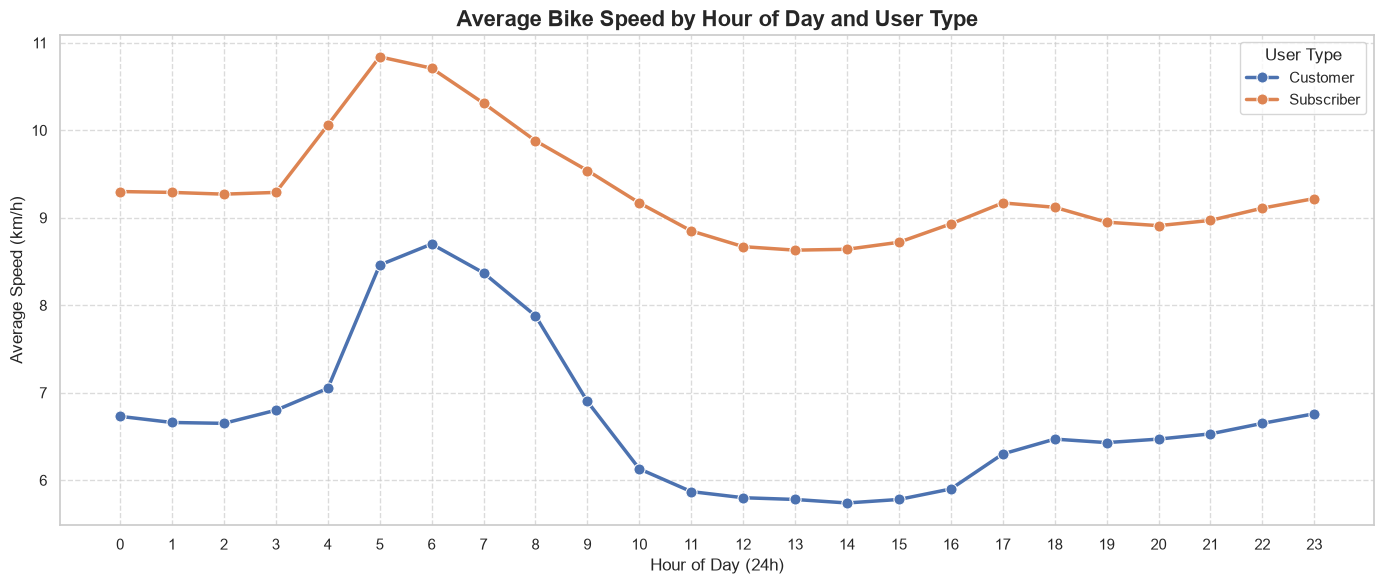

In [8]:
# Convert to pandas for seaborn plotting
plot_df = speed_over_time.to_pandas()

plt.figure(figsize=(14, 6))

# Line plot showing average speed by hour for each user type
sns.lineplot(
    data=plot_df, 
    x="start_hour", 
    y="avg_speed_kmh", 
    hue="user_type", 
    marker="o", 
    linewidth=2.5,
    markersize=8
)

plt.title("Average Bike Speed by Hour of Day and User Type", fontsize=16, fontweight='bold')
plt.xlabel("Hour of Day (24h)", fontsize=12)
plt.ylabel("Average Speed (km/h)", fontsize=12)
plt.xticks(range(0, 24)) # Show all 24 hours on x-axis
plt.legend(title="User Type", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

###  Answer to Question 6

**1. How does average speed differ between user types?**
*   **Subscribers ride significantly faster:** The average speed for Subscribers is **9.19 km/h** (median 9.31 km/h), compared to just **6.23 km/h** (median 6.31 km/h) for Customers. 
*   *Why?* This ~47% speed differential perfectly validates the "Commuter vs. Tourist" hypothesis. Subscribers are riding with purpose, know the city layout, and are motivated to commute efficiently. Customers are likely tourists or leisure riders using heavier bikes, stopping frequently for navigation or photos, and riding at a relaxed pace.

**2. How does average speed differ over time?**
*   **The Morning Commute Spike:** Even among Customers, we see a distinct speed spike during the morning rush hour (e.g., jumping to **8.37 km/h at 7 AM** and **7.88 km/h at 8 AM**). This suggests a subset of short-term users are also using the bikes to commute to work or school.
*   **The Midday Leisure Drop:** As the morning rush fades (9 AM – 11 AM), Customer speeds steadily decline (dropping to **5.87 km/h by 11 AM**). This aligns with leisure riding in crowded tourist areas (like Central Park), where riders must navigate around pedestrians, obey traffic signals, and stop frequently.

**Business Recommendation:** 
1. **Infrastructure & Safety:** The slower, more variable speeds of Customers during midday hours suggest these routes (especially around tourist hubs) are high-friction environments. The city/bike-share operator should prioritize protected bike lanes and clearer signage in these zones to prevent conflicts with pedestrians.
2. **Fleet Optimization:** Since Subscribers ride faster and more predictably, the operator could introduce a "Commute Tier" of lighter, faster bikes (e.g., e-bikes or premium lightweight frames) to capture more of this high-value, high-frequency demographic.